<div style="text-align: center;"> 
    <span style="font-size: 40px; font-weight: bold">
        Lập trình cho Khoa học dữ liệu - CQ2023/21
    </span>
</div>

<div style="text-align: center;"> 
    <span style="font-size: 24px; font-weight: bold">
        <i>
            01. Data Exploration
        </i>
    </span>
</div>

<div style="text-align: center;"> 
    <span style="font-size: 18px">
            Lê Võ Nhật Minh - 22120210
    </span>
</div>

<div style="text-align: right;">
    <span style="font-size: 14px">
        <i>
            Nov 29, 2025
        </i>
    </span>
</div>

---

### **I. Import các thư viện cần thiết và cấu hình mã nguồn**

Import các thư viện cần thiết

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Cấu hình đường dẫn data và index các cột

In [2]:
CSV_PATH = "../data/raw/ratings_Beauty.csv"   

COL_IDX_USER = 0
COL_IDX_PROD = 1
COL_IDX_RATING = 2
COL_IDX_TIME = 3

### **II. Load dữ liệu từ dataset**

Hàm đọc dữ liệu từng dòng sau đó tiến hành lưu vào mảng NumPy

In [3]:
def load_csv_np(path, delimiter=",", skip_header=1):
    with open(path, "r", encoding="utf-8") as f:
        lines = f.read().strip().splitlines()
    if skip_header:
        headers = lines[0]
        lines = lines[1:]
    rows = [line.split(delimiter) for line in lines]
    # chuyển về numpy array kiểu object để tránh lỗi khi có dữ liệu thiếu
    arr = np.array(rows, dtype=object)
    return arr, headers.split(delimiter) if skip_header else None # trả về cả header nếu có

Gọi hàm đọc dữ liệu

In [4]:
data_obj, headers = load_csv_np(CSV_PATH)
print("Number of rows:", data_obj.shape[0])
print("Number of columns:", data_obj.shape[1])

Number of rows: 2023070
Number of columns: 4


**1. Nhận xét tổng quan:**

- Đây là một dataset có số lượng bản ghi tương đối lớn với 2,023,070 dòng.

- Tuy nhiên số lượng cột lại ít với chỉ có 4 cột. Ý nghĩa từng cột được giải thích kĩ hơn ở bảng bên dưới.

| Trường      | Ý nghĩa                                                                 |
|-------------|-------------------------------------------------------------------------|
| UserId      | ID duy nhất của khách hàng (Customer Identification)                   |
| ASIN        | Mã định danh sản phẩm duy nhất của Amazon (Amazon Standard ID Number)  |
| Ratings     | Điểm đánh giá mức độ hài lòng (từ 1 đến 5)                             |
| Timestamp   | Thời điểm đánh giá (định dạng UNIX time)                               |


**2. Hướng phân tích khả thi:**

- UserId (Customer Identification – mã định danh khách hàng) 
    - Đại diện cho người dùng thực hiện đánh giá. 
    - Là một mã định danh duy nhất (unique ID).
    
    $\Rightarrow$ Dùng để phân tích hành vi người dùng, tần suất đánh giá hoặc xây dựng các mô hình gợi ý (Recommendation Systems).

- ASIN (Amazon Standard Identification Number – mã định danh sản phẩm):

    - Là mã sản phẩm duy nhất trên Amazon.

    - Được sử dụng để nhận diện từng sản phẩm trong tập dữ liệu.

    $\Rightarrow$ Cho phép phân tích mức độ phổ biến của sản phẩm và mức rating nhận được.

- Rating (Customer Rating — điểm đánh giá hài lòng từ 1 đến 5)

    - Giá trị nguyên từ 1 → 5, với ý nghĩa:

        - 1: Rất không hài lòng

        - 2: Không hài lòng

        - 3: Bình thường

        - 4: Hài lòng

        - 5: Rất hài lòng

    $\Rightarrow$ Dùng để phân tích phân phối đánh giá, mô hình hoá chất lượng sản phẩm và đánh giá hành vi người dùng.

- Timestamp (Thời điểm đánh giá – dạng UNIX timestamp)

    - Biểu diễn thời gian người dùng tạo đánh giá.

    - Có thể chuyển sang dạng datetime để phân tích theo:

        - Ngày, tháng, năm

        - Xu hướng rating theo thời gian

        - Seasonality (mua sắm theo mùa)

    $\Rightarrow$ Đây là yếu tố quan trọng cho feature engineering theo thời gian.

### **III. Chuyển đổi dữ liệu về dạng phù hợp để phân tích.**

Trích xuất từng cột để tiến hành xử lý

In [5]:
raw_user = data_obj[:, COL_IDX_USER]
raw_prod = data_obj[:, COL_IDX_PROD]
raw_rating = data_obj[:, COL_IDX_RATING]
raw_time = data_obj[:, COL_IDX_TIME]

#### **1. Chuẩn hóa định dạng các dòng có missing value.**

Hàm để đưa định dạng những dòng bị thiếu về `None`.

In [6]:
def norm_cell(x):
    if x is None:
        return None
    s = str(x).strip()
    if s == "" or s.lower() in ("na", "nan", "null", "\\n"):
        return None
    return s

####  **2. Hàm để mapping UserId từ dạng kí tự sang UserIndex dạng số.**

- Mục đích của việc làm này là để tăng tốc độ xử lý cho các phép toán trực quan hóa cũng như mô hình hóa sau này.
- Lấy ra danh sách các phần tử phân biệt làm map.
- UserIndex mới được tạo ra nhờ vào mapping index của phần tử tương ứng trong map vừa tạo

In [7]:
def map_to_indices_vectorized(col):
    unique_elements, inverse_indices = np.unique(
        col, 
        return_inverse=True
    )
    inverse_indices[col == None] = -1 # Nếu userId/productId bị thiếu, gán chỉ số là -1
    return inverse_indices, unique_elements

#### **3. Hàm để chuyển đổi các cột dữ liệu dạng số về định dạng phù hợp.**

- Dữ liệu dạng số sẽ được chuyển về kiểu `float` (sau khi gọi hàm `np.vectorize()` sẽ được chuyển về `np.float64`) nếu dòng nào có giá trị là `None` sẽ được chuyển về kiểu `np.nan`.
- Phải thêm cơ chế `try` và `except` bởi vì nếu có dòng nào đó không thể convert về kiểu dữ liệu dạng số sẽ gây ra lỗi.

In [8]:
def safe_float(x):
    try:
        return float(x)
    except:
        return np.nan

#### **4. Chuyển đổi dữ liệu của các cột.**

Xử lý missing value của các cột về định dạng phù hợp sử dụng `np.vectorize()`

In [9]:
raw_user = np.vectorize(norm_cell)(raw_user)
raw_prod = np.vectorize(norm_cell)(raw_prod)
raw_rating = np.vectorize(norm_cell)(raw_rating)
raw_time = np.vectorize(norm_cell)(raw_time)

Chuyển đổi cột `UserId` và `ProductId` thành dạng `np.int64` để phù hợp cho phân tích sau này.

In [10]:
user_idx_col, user_map = map_to_indices_vectorized(raw_user)
prod_idx_col, prod_map = map_to_indices_vectorized(raw_prod)

In [11]:
assert user_idx_col.dtype == np.dtype(np.int64)
assert type(user_map) == np.ndarray
assert prod_idx_col.dtype == np.dtype(np.int64)
assert type(prod_map) == np.ndarray

Chuyển đổi cột `Ratings` và `Timestamp` về định dạng số thực `np.float64` (do `np.float64` có thể chứa missing value bằng NaN)

In [12]:
rating_col = np.vectorize(safe_float)(raw_rating)
time_col = np.vectorize(safe_float)(raw_time)

In [13]:
assert rating_col.dtype == np.dtype(np.float64)
assert type(rating_col) == np.ndarray
assert time_col.dtype == np.dtype(np.float64)
assert type(time_col) == np.ndarray

### **IV. Khám phá dữ liệu**

#### **1. Tính hợp lệ của dữ liệu**

Đầu tiên, chúng ta tiến hành kiểm tra tính hợp lệ của dữ liệu. Có tồn tại giá trị nào bị thiếu hoặc không đúng với mô tả của dữ liệu không

In [14]:
print("- Số lượng đánh giá hợp lệ:", np.sum(~np.isnan(rating_col) & (rating_col >= 1.0) & (rating_col <= 5.0))) # Ratings phải từ 1 đến 5
print("- Số lượng timestamp hợp lệ:", np.sum(~np.isnan(time_col) & (time_col >= 0))) # Timestamp phải là số dương
print("- Số lượng đánh giá từ người dùng hợp lệ:", np.sum(user_idx_col != -1))
print("- Số lượng đánh giá về sản phẩm hợp lệ:", np.sum(prod_idx_col != -1))

- Số lượng đánh giá hợp lệ: 2023070
- Số lượng timestamp hợp lệ: 2023070
- Số lượng đánh giá từ người dùng hợp lệ: 2023070
- Số lượng đánh giá về sản phẩm hợp lệ: 2023070


Có vẻ đây là một bộ dữ liệu rất sạch khi không tồn tại bất kì bản ghi bất hợp lệ nào.

Tiếp theo, ta sẽ tiến hành khảo sát số lượng khách hàng duy nhất và số lượng sản phẩm duy nhất có trong bộ dữ liệu

In [15]:
print("- Số lượng người dùng duy nhất:", user_map.shape[0])
print("- Số lượng sản phẩm duy nhất:", prod_map.shape[0])

- Số lượng người dùng duy nhất: 1210271
- Số lượng sản phẩm duy nhất: 249274


$\Rightarrow$ Bộ dữ liệu càng củng cố rằng Amazon thật sự là một sàn thương mại điện tử vô cùng lớn với hơn 1,2 triệu khách hàng và hơn 249,000 dòng sản phẩm.

#### **2. Đặt ra các câu hỏi và tiến hành phân tích**

***Note***: Trong phần này để bù trừ vào những thiếu hụt trong kiến thức miền (domain knowledge), các mô hình LLM đã được sử dụng để hỗ trợ phân tích chuyên sâu hơn (ví dụ: góc nhìn kinh tế). Sau đó kiến thức sẽ được kiểm tra lại thông qua search engine như Google để đảm bảo tính xác thực của insight.

##### **a. Khám phá cột UserId**
***<u>Câu hỏi 1</u>: Tỉ lệ đánh giá sản phẩm thay đổi như thế nào qua từng top-k (%) người dùng?***
- Lý do cho câu hỏi:
    - Xác định “power users” — nhóm những người đóng góp nhiều interaction nhất (review/purchase/interaction).
    - Ưu tiên marketing & chăm sóc — tập trung khuyến mãi, loyalty cho nhóm này thường hiệu quả.
    - Phát hiện bất thường — user có số dòng quá lớn có thể là: spammer, bot, tài khoản doanh nghiệp.
    - Hiểu phân phối dữ liệu — kiểm tra xem doanh số/interaction có bị hội tụ vào nhóm nhỏ (Pareto) hay phân tán (long-tail).
    - Định hướng mô hình — quyết định sampling, weighting cho recommender/modeling (ví dụ downsample heavy users).
- Kết quả đạt được khi trả lời insight câu hỏi này:
    - Tập trung chăm sóc: nhóm những user này có thể được ưu tiên cho chương trình khách hàng thân thiết, coupon cá nhân.
    - Điều chỉnh dữ liệu: nếu nhóm các top users chiếm quá nhiều proportion → cần cân nhắc downsampling khi huấn luyện model để tránh bias.
    - Phát hiện gian lận: user có hàng nghìn dòng nhưng toàn pattern lạ → kiểm tra xem có automation/spam hay account shared.
    - Định hướng kho & inventory: nếu nhóm top users thường mua những nhóm sản phẩm nhất định → ưu tiên tồn kho cho nhóm đó.
- Để trả lời câu hỏi này:
    - Sử dụng cột UserId để đếm số rating của từng user.
    - Sắp xếp user theo tổng số rating giảm dần.
    - Tính phân phối tích lũy (cumulative distribution) của các top-k% user, với k = 10%, 20%, …, 100%.
    - Biểu diễn qua bảng hoặc biểu đồ để xem
<u>Cần lưu ý</u>: Trên hệ thống của Amazon, tại một thời điểm chỉ tồn tại một bản ghi liên quan đến việc người dùng thực hiện đánh giá cho sản phẩm. Do đó số lượng lượt đánh giá ở đây chính là số lượt đánh giá của các khách hàng dành cho các dòng sản phẩm.

In [16]:
# Đếm số lượng đánh giá của mỗi user
unique_users, user_counts = np.unique(user_idx_col, return_counts=True)
# Sắp xếp mảng chỉ số theo số lượng đánh giá giảm dần
sorted_cnts_user_idx = np.argsort(-user_counts)

Hàm lấy tỉ lệ phần trăm đánh giá của top k (%) người dùng so với tổng thể.

In [17]:
def get_top_percentile_share(sorted_element_cnt, num_element,  percentile=0.1):
    k = max(1, int(np.ceil(percentile * sorted_element_cnt.shape[0])))
    topk_counts = sorted_element_cnt[:k] 
    
    top_percentile_share = topk_counts.sum() / num_element
    
    # Hàm này cũng có thể được dùng để trả về tỉ lệ phần trăm đánh giá cho nhóm top k% sản phẩm
    return top_percentile_share # Trả về tỉ lệ phần trăm đánh giá do nhóm top k% người dùng tạo ra

percentile_user_share_bin = np.array([get_top_percentile_share(user_counts[sorted_cnts_user_idx], user_idx_col.shape[0], percentile=p / 10) for p in range(1,11)])

Trực quan hóa kết quả, ở đây sẽ tiến hành chia theo từng khoảng có độ rộng là 10% cho biểu đồ phân phối tích lũy.

In [18]:
def percentile_share_display(percentile_share_bin, plot_title, xlabel, bins=None):
    x_pos = np.arange(len(percentile_share_bin)) 
    plt.figure(figsize=(14, 6))

    # Vẽ biểu đồ cột (Y-axis là giá trị gốc)
    bars = plt.bar(x_pos, percentile_share_bin, color='teal', alpha=0.8)

    # Vòng lặp này chỉ dùng để định vị và định dạng văn bản (không phải tính toán)
    for bar, percent in zip(bars, percentile_share_bin * 100):  # Nhân với 100 để chuyển sang %
        height = bar.get_height()
        
        # Định dạng chuỗi: 2 chữ số sau dấu phẩy (:.2f)
        text_label = f'{percent:.2f}%'
        
        # Định vị và thêm văn bản
        plt.text(
            bar.get_x() + bar.get_width() / 2.,  # X-position (ở giữa cột)
            height * 1.01,                       # Y-position (hơn đỉnh cột một chút)
            text_label,
            ha='center',                         # Căn chỉnh ngang: Center
            va='bottom',                         # Căn chỉnh dọc: Bottom
            fontsize=9,
            fontweight='bold'
        )

    # --- Tùy chỉnh biểu đồ ---
    if bins is not None:
        plt.xticks(x_pos, [f'Top {bin}%' for bin in bins], rotation=45, ha='right')
    else:
        plt.xticks(x_pos, [f'Top {i * 10}%' for i in range(1,11)], rotation=45, ha='right')
    plt.title(plot_title, fontsize=16)
    plt.ylabel(xlabel, fontsize=12)
    plt.xlabel('Top k%', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

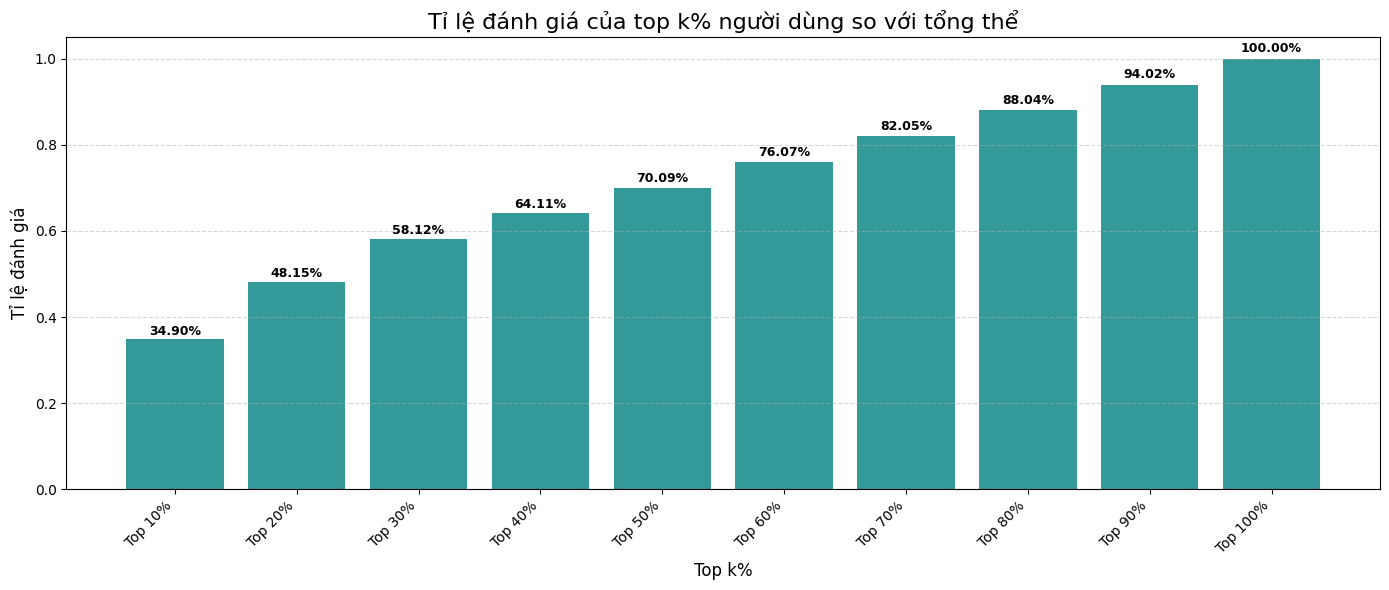

In [19]:
percentile_share_display(percentile_share_bin=percentile_user_share_bin, plot_title='Tỉ lệ đánh giá của top k% người dùng so với tổng thể', xlabel='Tỉ lệ đánh giá')

***Insight 1: Sự chênh lệch rất lớn về mức độ hoạt động (Distribution Skewness)***

Biểu đồ cho thấy sự phân bố không đồng đều điển hình trong các hệ thống gợi ý (Recommender Systems) hoặc mạng xã hội:
- Top 10% người dùng tích cực nhất đã đóng góp tới 34.90% tổng lượng đánh giá.
- Top 20% người dùng đóng góp gần một nửa tổng lượng dữ liệu (48.15%).

$\Rightarrow$ Điều này cho thấy một nhóm nhỏ "Power Users" (người dùng tích cực) đang tạo ra phần lớn nội dung/tương tác cho hệ thống. Dưới góc độ tâm lý học, họ có thể là những "Beauty Junkie" - đây chính là những người "nghiện mỹ phẩm". Họ mua thử hầu hết các sản phẩm mới ra mắt.

***Insight 2: Sự "lấn át" của nhóm dẫn đầu so với nhóm cuối (The Long Tail)***

Một con số rất thú vị khi so sánh đầu và cuối:

- Top 10% đầu tiên đóng góp ~35%.
- 50% người dùng cuối cùng (từ mốc 50% đến 100%) chỉ đóng góp: 100% - 70.09% = 29.91%.

$\Rightarrow$ Chỉ riêng 10% người dùng tích cực nhất đã có lượng đóng góp lớn hơn tổng cộng của 50% người dùng ít hoạt động nhất (34.9% so với 29.9%). đây có thể là hiệu ứng từ chương trình Amazon Vine, trong đó Amazon thường gửi mỹ phẩm miễn phí cho nhóm reviewer uy tín (Vine Voices) để họ đánh giá sản phẩm mới. Đây là lý do một nhóm nhỏ người dùng có số lượng đánh giá khổng lồ.

***Insight 3: Quy luật tiệm cận Pareto (80/20)***

Mặc dù không khớp chính xác con số 80/20 (20% người dùng tạo ra 80% kết quả), nhưng xu hướng này khá gần gũi:

- Top 30% người dùng đã tạo ra gần 60% (58.12%) dữ liệu.
- Top 50% người dùng tạo ra 70% dữ liệu.
- Nửa còn lại của người dùng (50% sau) chỉ đóng góp 30% dữ liệu.

***Insight 4: Tốc độ tăng trưởng giảm dần (Diminishing Returns)***

Nhìn vào độ dốc của các cột, ta thấy mức đóng góp biên (marginal contribution) giảm dần:

- Nhóm 10% đầu tiên thêm vào ~35%.
- Nhóm 10% thứ hai (từ 10% lên 20%) thêm vào: 48.15 - 34.90 $\approx$ 13.25%.
- Nhóm 10% cuối cùng (từ 90% lên 100%) chỉ thêm vào: 100 - 94.02 $\approx$ 5.98%.

***Kết luận: Ý nghĩa thực tế (Insight for Data Science/Business)***

Vì đây là dữ liệu cho bài toán hệ thống gợi ý, vì vậy cần chú ý một số đặc điểm sau

- Độ thiên lệch của mô hình (Model Bias): Mô hình máy học sẽ học chủ yếu từ sở thích của nhóm Top 10-20% người dùng này. Các gợi ý đưa ra sẽ có xu hướng phục vụ tốt cho nhóm "Power Users" nhưng có thể không chính xác với nhóm người dùng ít hoạt động (vấn đề Popularity Bias).
- Vấn đề Cold Start: 50% người dùng cuối có rất ít dữ liệu (Sparse Data), khiến việc cá nhân hóa cho họ cực kỳ khó khăn.
- Chiến lược giữ chân (Retention): Hệ thống phụ thuộc quá nhiều vào nhóm Top 10%. Nếu nhóm này rời bỏ nền tảng, lượng dữ liệu tương tác sẽ sụt giảm nghiêm trọng (mất hơn 1/3 dữ liệu chỉ vì 10% người dùng). Do đó phải có chiến lược giữ chân phù hợp cho nhóm người dùng này

##### **b. Khám phá cột ProductId**
***<u>Câu hỏi 2</u>: Tỉ lệ đánh giá sản phẩm thay đổi như thế nào qua từng top-k (%) sản phẩm?***
- Lý do cho câu hỏi:
    - Xác định nhóm “hot products” (sản phẩm lõi của thị trường): Những sản phẩm được đánh giá nhiều nhất thường là các sản phẩm bán chạy nhất, có độ phủ cao, hoặc là sản phẩm chủ lực của từng danh mục. Đây là nhóm sản phẩm mà marketplace cần ưu tiên hiển thị, quảng bá và đảm bảo tồn kho.

    - Hiểu cấu trúc long-tail của thị trường: Amazon đặc trưng bởi hiệu ứng long-tail - một số ít sản phẩm có lượng review cực lớn, phần còn lại cực kỳ nhiều sản phẩm nhưng review rất ít. Việc phân tích top-k (%) giúp đánh giá mức độ “tập trung” này.

    - Tối ưu thuật toán gợi ý (Recommender System): Nếu phần lớn dữ liệu tập trung vào top 1–5% sản phẩm thì mô hình dễ thiên vị các sản phẩm nổi tiếng, các sản phẩm tail dễ bị “bỏ quên”. Insight này giúp quyết định có cần phải sampling lại dữ liệu, “boost” sản phẩm mới, dùng thuật toán chuyên xử lý sparse data (ALS, BPR…).

    - Hỗ trợ chiến lược kinh doanh & vận hành: ưu tiên tồn kho cho nhóm sản phẩm top, tối ưu vị trí kho hàng, xác định nhóm sản phẩm nên chạy quảng cáo PPC (Pay per click - loại quảng cáo này sẽ được trả tiền cho mỗi lần nhấp).
- Kết quả đạt được khi trả lời insight câu hỏi này:
    - Mức độ tập trung của nhu cầu tiêu dùng, ví dụ:
        - Top 1% sản phẩm chiếm 20–30% tổng review → thị trường tập trung cao, vài sản phẩm chi phối phần lớn nhu cầu.
        - Nếu Top 10% sản phẩm chỉ chiếm 15% review → thị trường phân tán, quyết định chiến lược marketing sẽ khác.

    - Chiến lược ưu tiên hiển thị và quảng cáo
        - Nhóm sản phẩm top review → có ROI (lợi tức đầu tư, là chỉ số dùng để đo lường phần trăm lợi nhuận mà doanh nghiệp thu được từ một khoản đầu tư đã bỏ ra) tốt khi chạy quảng cáo.
        - Nhóm sản phẩm tail → cần chiến dịch tăng hiển thị.

    - Chiến lược tồn kho (inventory planning)
        - Hot-product → cần đảm bảo không thiếu hàng.
        - Long-tail → chỉ nên giữ mức tồn kho thấp.

    - Tối ưu mô hình gợi ý: Nếu top 5% sản phẩm chiếm 40–50% interaction → mô hình collaborative filtering sẽ rất bias → Cần re-weighting hoặc trình tự negative sampling phù hợp.
- Để trả lời câu hỏi này:
    - Sử dụng cột ProductId để đếm số rating trên từng dòng sản phẩm.
    - Sắp xếp sản phẩm theo tổng số rating giảm dần.
    - Tính phân phối tích lũy (cumulative distribution) của các top-k% sản phẩm, với k = 10%, 20%, …, 100%.
    - Biểu diễn qua bảng hoặc biểu đồ để xem.

In [20]:
# Đếm số lượng đánh giá của cho mỗi sản phẩm
unique_prods, prod_counts = np.unique(prod_idx_col, return_counts=True)
# Sắp xếp mảng chỉ số theo số lượng đánh giá giảm dần
sorted_cnts_prod_idx = np.argsort(-prod_counts)

Hàm lấy tỉ lệ phần trăm lượt đánh giá của top k (%) sản phẩm so với tổng thể.

In [21]:
percentile_prod_share_bin = np.array([get_top_percentile_share(prod_counts[sorted_cnts_prod_idx], prod_idx_col.shape[0], percentile=p / 10) for p in range(1,11)])

Trực quan hóa kết quả, ở đây sẽ tiến hành chia theo từng khoảng có độ rộng là 10% cho biểu đồ phân phối tích lũy.

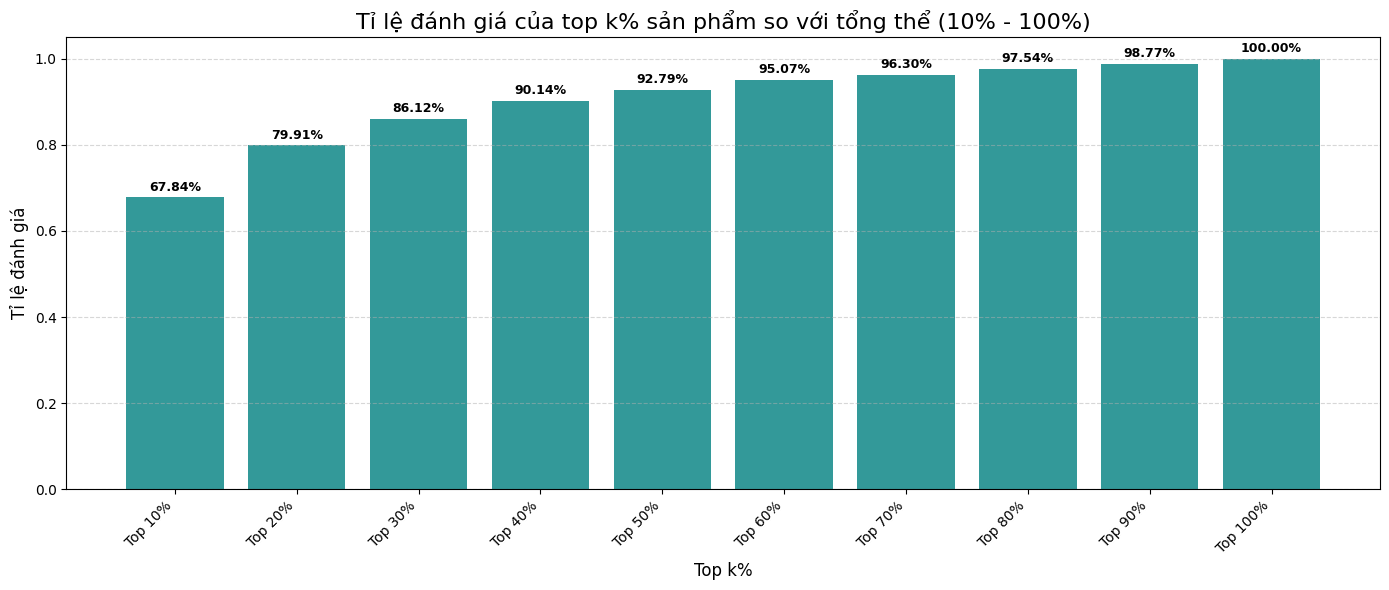

In [22]:
percentile_share_display(percentile_prod_share_bin, 'Tỉ lệ đánh giá của top k% sản phẩm so với tổng thể (10% - 100%)', 'Tỉ lệ đánh giá')

Ta thấy gần 68% số lượt đánh giá là dành cho top 10% sản phẩm. Chính vì vậy, ta sẽ tiếp tục đi sâu vào trực quan cho top 10% người dùng này với độ rộng của phân phối tích lũy là khoảng 1%.

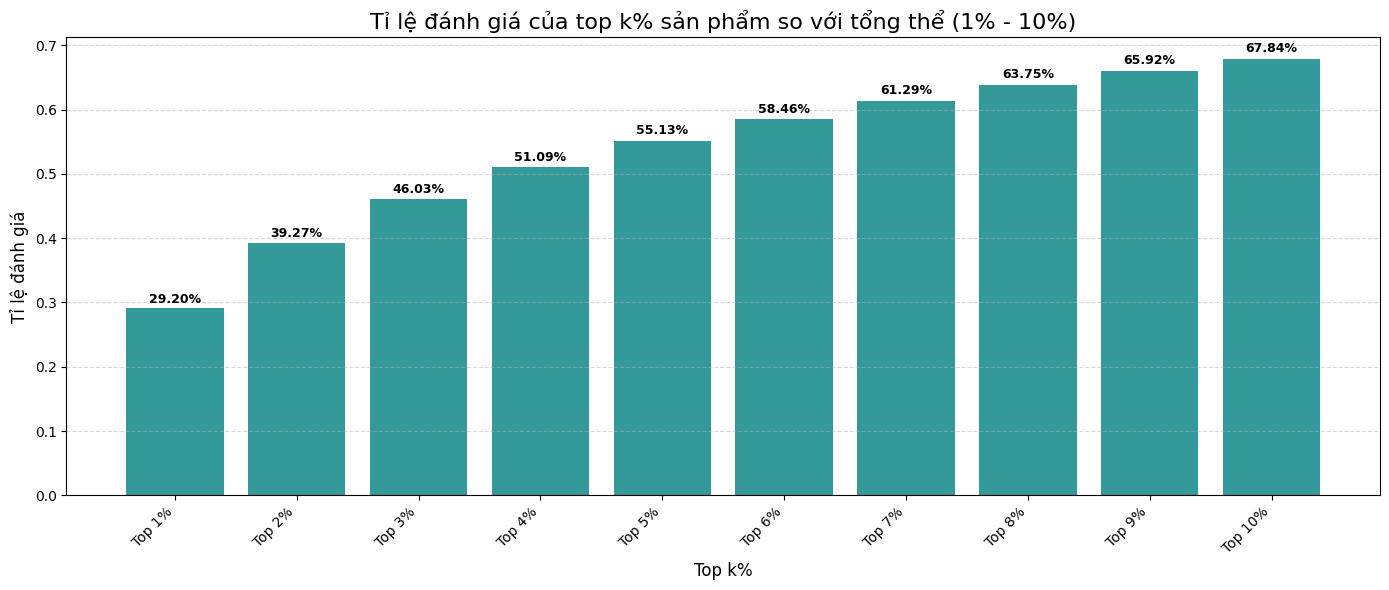

In [23]:
top_10_percent_prod_share_bin = np.array([get_top_percentile_share(prod_counts[sorted_cnts_prod_idx], prod_idx_col.shape[0], percentile=p / 100) for p in range(1,11)])
percentile_share_display(top_10_percent_prod_share_bin, 'Tỉ lệ đánh giá của top k% sản phẩm so với tổng thể (1% - 10%)', 'Tỉ lệ đánh giá', [p for p in range(1,11)])

Hai biểu đồ này thể hiện sự phân bố về mức độ phổ biến của sản phẩm (Item Popularity Distribution) với mức độ chênh lệch vô cùng cực đoan.

***Insight 1. Sự thống trị của các "Sản phẩm Bom tấn" (Blockbusters)***

Nhìn vào biểu đồ thứ hai (Top 1% - 10%):
* Top 1% sản phẩm đã chiếm lĩnh tới 29.20% tổng lượng tương tác/đánh giá.
* Top 5% sản phẩm đã chiếm quá nửa thị phần tương tác 55.13%.

$\Rightarrow$  Trong ngành làm đẹp, người dùng thường ưu tiên những thương hiệu phổ biến và có độ nhận diện cao để sử dụng. Chính vì vậy mới xuất hiện dấu hiệu của một thị trường "Winner-takes-all" (Người thắng ăn tất). Một lượng rất nhỏ sản phẩm (có thể là Best-sellers) đang thu hút phần lớn sự chú ý của người dùng.

***Insight 2. Quy luật Pareto (80/20) được thể hiện chuẩn xác đến kinh ngạc***

Nhìn vào biểu đồ thứ nhất (Top 10% - 100%):
* Tại mốc Top 20, tỷ lệ đánh giá tích lũy là 79.91% (gần như tuyệt đối là 80%).

$\Rightarrow$ Đây là ví dụ sách giáo khoa hoàn hảo cho Quy luật 80/20: 20% sản phẩm tạo ra 80% tương tác. Điều này cho thấy kho hàng trên Amazon đang phụ thuộc rất lớn vào nhóm 20% sản phẩm chủ lực này.

***Insight 3. Phân phối với cái "đuôi dài" bị chết (Dead Long Tail)***

Sự chênh lệch giữa nhóm đầu và nhóm cuối là rất lớn:
* Top 40% sản phẩm đã chiếm 90.14% tổng đánh giá.
* Suy ra: 60% sản phẩm còn lại chỉ chia nhau vỏn vẹn ~10% sự chú ý.
* Thậm chí, 50% sản phẩm cuối cùng (từ mốc 50% đến 100%) chỉ chiếm khoảng 7.2%.

$\Rightarrow$ Hơn một nửa các dòng sản phẩm trên Amazon là các sản phẩm "ít người biết đến" (niche items) hoặc sản phẩm chết. Rất ít người dùng tương tác với chúng.

***Insight 4. Ý nghĩa đối với bài toán Gợi ý (Recommendation Insight)***

Từ biểu đồ này, người xây dựng hệ thống đề xuất có thể nhìn thấy ngay các thách thức sau:

1.  Popularity Bias (Thiên kiến phổ biến) cực nặng:
    Nếu huấn luyện mô hình máy học trên dữ liệu này mà không xử lý, mô hình sẽ chỉ học cách gợi ý các sản phẩm trong Top 5% hoặc Top 20%. Nó sẽ luôn gợi ý các món "Best-seller" cho tất cả mọi người vì xác suất đúng cao nhất, làm giảm tính cá nhân hóa và sự đa dạng.

2.  Item Cold-Start (Khởi động lạnh cho sản phẩm):
    Với 60% sản phẩm nằm ở đuôi (ít dữ liệu), mô hình Collaborative Filtering (Lọc cộng tác) sẽ hoạt động rất tệ vì không có đủ lịch sử tương tác để tìm ra sự tương đồng.

3.  Chiến lược kinh doanh
    * An toàn: Gợi ý các sản phẩm Top 20% sẽ đảm bảo tỷ lệ chuyển đổi (Conversion Rate) ở mức ổn định.
    * Rủi ro/Cơ hội: Thách thức thực sự của hệ thống gợi ý là làm sao để "khai quật" được các sản phẩm tốt nằm trong nhóm 80% còn lại (Long tail) để giới thiệu đúng người, giúp tăng doanh số cho các mặt hàng ít phổ biến này.

Trước khi tiến hành khám phá cột Raiting và Timestamp, ta sẽ tiến hành chuyển đổi kiểu dữ liệu của hai cột này cho phù hợp. Bởi vì dữ liệu không có dòng nào có cột Rating và Timestamp bị thiếu, chính vì vậy, ta sẽ chuyển đổi hai cột này sang kiểu dữ liệu khác (`int8` cho Rating và `datetime64[s]` cho Timestamp) để cải thiện hiệu suất tính toán.

In [24]:
rating_col = rating_col.astype(np.int8) # Rating từ 1 đến 5, dùng int8 để tiết kiệm bộ nhớ
# Phải convert sang int64 trước khi convert sang datetime64[s] để tránh lỗi
time_col = time_col.astype(np.int64).astype('datetime64[s]') # Timestamp dùng datetime64[s] để thao tác với thời gian dễ dàng hơn

##### **c. Khám phá cột Rating**
***<u>Câu hỏi 3</u>: Rating có tỉ lệ phân phối như thế nào?***
- Lý do cho câu hỏi:

    - Kiểm tra chất lượng trải nghiệm người dùng (UX) và sản phẩm trên nền tảng
        * Nếu đa số đánh giá là 4–5 sao → khách hàng hài lòng → nền tảng có khả năng đề xuất tốt và uy tín tốt.
        * Nếu 1–2 sao nhiều → hệ thống đề xuất hoặc chất lượng sản phẩm đang có vấn đề.

    - Phục vụ mô hình gợi ý (recommender systems) - Mức rating phân phối ảnh hưởng đến:

        * loss function (implicit feedback vs explicit rating)
        * cách normalize rating
        * cách đánh trọng số cho high/low rating
        * chiến lược negative sampling

        Nếu rating lệch quá mạnh về 5 → có thể convert sang implicit feedback (like/dislike).

    - Hỗ trợ quyết định chiến lược kinh doanh - nếu nhiều sản phẩm 1–2 sao:
        * cần kiểm tra nhà bán, tạm khóa sản phẩm, hoặc yêu cầu cải thiện chất lượng.
        Nếu đa số rating cao:
        * có thể giới thiệu thêm sản phẩm tương tự, gợi ý cross-selling.

- Kết quả đạt được khi trả lời insight câu hỏi này:
    - Tổng quan chất lượng sản phẩm trên nền tảng.

    - Đánh giá mức độ thiên lệch của người dùng

        Nếu tỉ lệ rating:
        * 5 sao quá nhiều
        * 3 sao rất ít
        → người dùng có thiên hướng chỉ đánh giá khi cực kỳ hài lòng (hoặc có động lực khác).

        Điều này giúp:
        * thiết kế tốt hơn hệ thống gợi ý review,
        * điều chỉnh cách hiển thị rating.

    - Phát hiện sản phẩm có vấn đề - nếu sản phẩm có quá nhiều review với rating thấp, phải ngay lập tức liên hệ với bên bán hàng để tìm ra hướng giải quyết phù hợp, đảm bảo uy tín của hệ thống.

    - Cải thiện UI/UX review - Tỉ lệ rating thấp có thể cho biết: khách hàng khó chịu vì giao diện, hoặc khó đánh giá, hoặc quy trình nhận xét phức tạp.

    - Cải thiện chất lượng mô hình dự đoán - nếu rating bị lệch → mô hình Regression sẽ kém → nên chuyển sang: implicit feedback, ranking models, hoặc normalize rating trước khi train.

- Để trả lời câu hỏi này:
    - Sử dụng cột Rating và đếm số lượng ở từng mức đánh giá

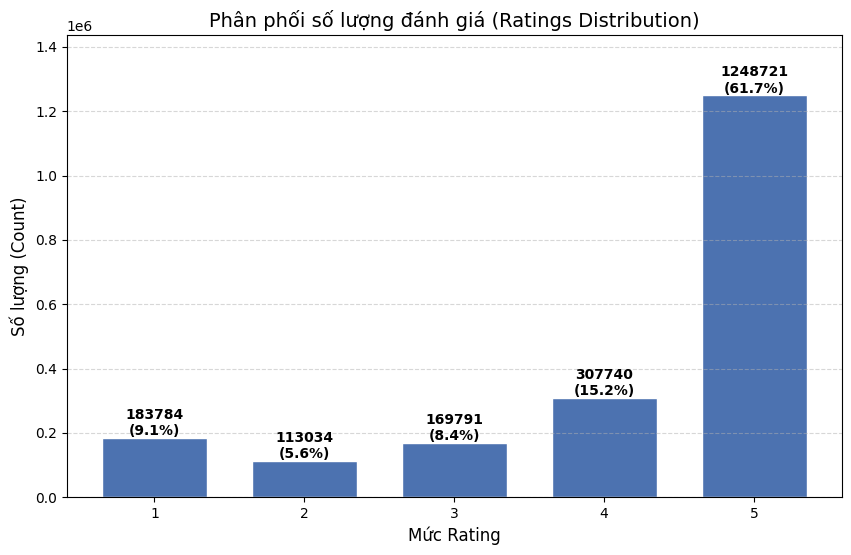

In [25]:
# np.unique trả về các giá trị rating và số lần xuất hiện (counts)
ratings, rating_counts = np.unique(rating_col, return_counts=True)

#  Vẽ biểu đồ
plt.figure(figsize=(10, 6))

# Dùng plt.bar thay vì plt.hist để kiểm soát tốt hơn các cột số nguyên
bars = plt.bar(ratings, rating_counts, color='#4c72b0', edgecolor='white', width=0.7)

# Thêm nhãn số lượng và phần trăm lên đỉnh cột
total = sum(rating_counts)
for bar, count in zip(bars, rating_counts):
    height = bar.get_height()
    percentage = (count / total) * 100
    
    # Hiển thị: Số lượng (Phần trăm%)
    label = f"{count}\n({percentage:.1f}%)"
    
    plt.text(
        bar.get_x() + bar.get_width() / 2., 
        height, 
        label, 
        ha='center', 
        va='bottom', 
        fontsize=10, 
        fontweight='bold'
    )

# Tùy chỉnh trục và tiêu đề
plt.title('Phân phối số lượng đánh giá (Ratings Distribution)', fontsize=14)
plt.xlabel('Mức Rating', fontsize=12)
plt.ylabel('Số lượng (Count)', fontsize=12)
# Thêm khoảng đệm 15% vào phía trên trục Y
plt.margins(y=0.15)
plt.xticks(ratings) # Đảm bảo trục X chỉ hiện các số 1, 2, 3...
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

 **Insight 1: Tổng quan về phân phối**
* Dữ liệu cho thấy sự mất cân bằng cực lớn (High Class Imbalance). Mức rating 5 sao chiếm tới 61.7 (hơn 1.2 triệu lượt).
* *Dữ liệu đánh giá có thiên hướng tích cực (Positivity Bias): Tổng lượng đánh giá tích cực (4 sao và 5 sao) chiếm khoảng 76.9%.
* Biểu đồ có xu hướng hình chữ J (hoặc phân phối lệch trái - left skewed), trong đó:
    * Cực hài lòng (5 sao) chiếm đa số.
    * Cực không hài lòng (1 sao - 9.1%) cao hơn mức "hơi không hài lòng" (2 sao - 5.6%) và xấp xỉ mức trung bình (3 sao - 8.4%).
    * Điều này phản ánh tâm lý người dùng: Họ thường chỉ bỏ thời gian viết review khi cực kỳ thích hoặc cực kỳ ghét. Những trải nghiệm "bình thường" (2-3 sao) thường bị bỏ qua.

 **Insight 2: Chất lượng trải nghiệm người dùng (UX) và sản phẩm**
* Đa số người dùng (gần 77%) có trải nghiệm tốt (4-5 sao). Điều này chứng tỏ nền tảng có độ uy tín cao, sản phẩm nhìn chung chất lượng tốt và hệ thống logistics/CSKH hoạt động hiệu quả.
* Một khía cạnh khác khá đáng lưu tâm là hiệu ứng "Holy Grail" (Chân ái). Trong ngành làm đẹp, khi người dùng tìm được một sản phẩm hợp da (hết mụn, trắng da...), họ cực kỳ hạnh phúc và sẵn sàng chấm 5 sao kèm những lời khen "có cánh".
* Tuy nhiên, tỉ lệ 1 sao (9.1%) không phải là nhỏ (gần 184k lượt). Dù tỉ lệ thấp so với tổng thể, nhưng con số tuyệt đối lớn cho thấy vẫn có một lượng lớn khách hàng gặp trải nghiệm rất tệ (hàng giả, hỏng hóc, giao sai...)
* Trong ngành mỹ phẩm, 1 sao thường không phải do giao hàng chậm, mà là do Kích ứng da (Breakout/Allergy) hoặc Nghi ngờ hàng giả (Fake product).

**Insight 3: Phục vụ mô hình gợi ý (Recommender Systems)**
* Việc 5 sao chiếm 61.7% sẽ khiến mô hình máy học (Machine Learning) bị thiên kiến (bias). Nếu dùng mô hình hồi quy đơn thuần, mô hình sẽ có xu hướng dự đoán toàn bộ là 4.8 - 5.0 để tối ưu hóa hàm loss (MSE), dẫn đến việc gợi ý không còn tính cá nhân hóa cao.
* Chiến lược xử lý:
    * Chuyển sang Implicit Feedback: Do rating bị lệch quá nhiều về 5, sự khác biệt giữa các mức rating không còn nhiều ý nghĩa (người dùng đánh 5 sao có thể là "rất thích" hoặc chỉ là "thấy ổn"). Nên convert bài toán thành Binary Classification (Thích/Không thích).
    * Chuẩn hóa Rating: Cần chuẩn hóa rating theo từng user (trừ đi trung bình rating của user đó) để loại bỏ tính cách "dễ tính" hay "khó tính" của từng người.
    * Negative Sampling: Cần chọn mẫu âm (negative samples) cẩn thận từ nhóm 1-2 sao để mô hình học được thế nào là "không thích".

**Insight 4: Hỗ trợ quyết định chiến lược kinh doanh**
* Với nhóm 1 sao (9.1%): Cần hệ thống cảnh báo tự động. Nếu một sản phẩm hoặc nhà bán hàng có tỉ lệ 1 sao tăng đột biến, cần "gắn cờ" (flag) để kiểm tra chất lượng hoặc tạm khóa.
* Với nhóm 5 sao (61.7%): Đây là cơ hội vàng để Cross-selling/Up-selling. Khi khách hàng đã hài lòng, hệ thống nên đẩy mạnh việc gợi ý các sản phẩm phụ kiện đi kèm hoặc các sản phẩm tương tự có biên lợi nhuận (tỷ lệ phần trăm lợi nhuận trên doanh thu) cao hơn.

**Insight 5: Đánh giá mức độ thiên lệch của người dùng (User Bias)**
* Tỉ lệ 3 sao (8.4%) và 2 sao (5.6%) rất thấp.
* Người dùng trên nền tảng này ít khi đánh giá trung lập. Họ có xu hướng phân cực.
* Có thể giao diện đánh giá hiện tại đang khuyến khích việc chọn 5 sao mặc định (ví dụ: các sao đã sáng sẵn). Nếu muốn dữ liệu phân hóa tốt hơn (để phân loại sản phẩm xuất sắc vs sản phẩm khá), có thể thay đổi thang đo hoặc yêu cầu nhập lý do chi tiết hơn khi đánh giá 5 sao.

##### **d. Khám phá cột Timestamp**

***<u>Câu hỏi 4</u>: Sự thay đổi của số lượt đánh giá theo từng năm.***
- Lý do cho câu hỏi:
    - Xác định xu hướng hoạt động của người dùng theo thời gian: năm nào mức độ review tăng mạnh, năm nào giảm → giúp hiểu mức độ tương tác của khách hàng.
    - Kiểm tra tính mùa vụ: có năm nào bùng nổ do COVID, Black Friday, tăng trưởng thương mại điện tử, ra mắt sản phẩm mới…
    - Hỗ trợ phòng ban marketing & business planning đưa ra chiến lược phù hợp: nếu năm sau dự đoán tăng trưởng review → chuẩn bị nhiều nhân sự moderation hoặc cải thiện hệ thống gợi ý sản phẩm.
    - Giúp phát hiện bất thường: một năm đột ngột giảm mạnh review → có thể do thay đổi chính sách review, thay đổi UI/UX, hoặc spam/bot bị loại bỏ.
    - Hỗ trợ data validation: nếu năm nào đó gần như không có review → có thể do dữ liệu bị thiếu hoặc lỗi → cần kiểm tra lại quá trình crawl/data pipeline.
- Kết quả đạt được khi trả lời insight câu hỏi này:
    - Biết được xu hướng tăng trưởng người dùng thật và mức độ tương tác mỗi năm.
    - Xác định giai đoạn peak khi khách hàng review nhiều nhất → hỗ trợ chiến lược marketing.
    - Nếu có năm đột biến giảm → có thể điều chỉnh lại chính sách review, UI/UX, khuyến mãi, recommendation.
    - Phân tích vòng đời người dùng: nếu review tăng đều mỗi năm → đó là dấu hiệu nền tảng phát triển tốt.
    - Cải thiện định hướng mô hình recommender:
        - Nếu dữ liệu các năm gần gần ít → có thể gộp
        - Nếu dữ liệu quá mất cân bằng theo năm → cần sample lại để tránh bias.
    - Tạo cơ sở để xây dựng dự đoán (forecast) số lượng review trong những năm tiếp theo.
- Để trả lời câu hỏi này:
    - Sử dụng cột Timestamp và đếm số lượt đánh giá qua từng năm.
    - Trực quan hóa bằng biểu đồ cột.
    - Sử dụng cột Timestamp và đếm số lượt đánh giá theo từng tháng.
    - Trực quan hóa bằng biểu đồ đường.

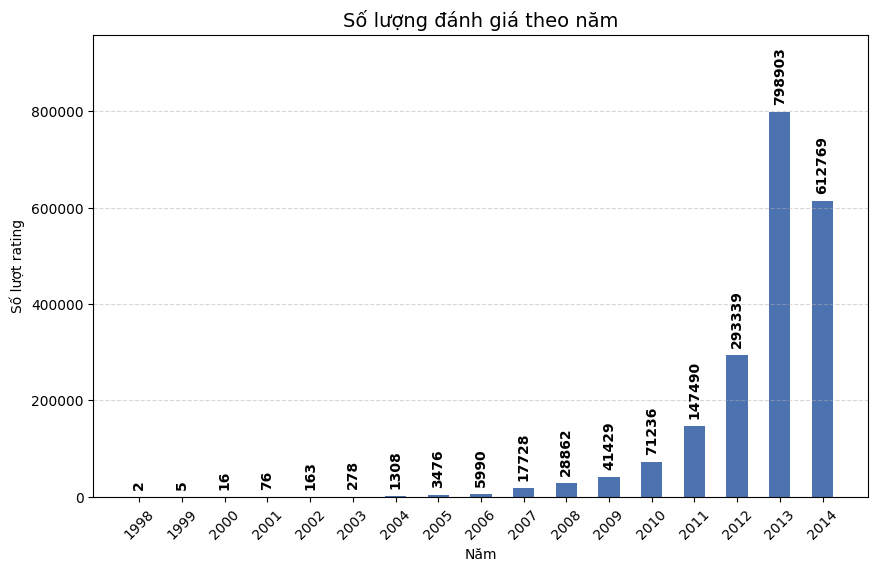

In [26]:
# Chuyển đổi toàn bộ mảng về độ chính xác theo NĂM [Y]
# NumPy sẽ tự động cắt bỏ tháng ngày, chỉ giữ lại năm
years_only = time_col.astype('datetime64[Y]')

# Đếm số lượng (np.unique trả về đã sắp xếp theo thời gian)
unique_years, year_counts = np.unique(years_only, return_counts=True)

# Chuyển về string để vẽ biểu đồ cho dễ (VD: '2020')
year_labels = np.datetime_as_string(unique_years, unit='Y')

# --- Vẽ biểu đồ Cột ---
plt.figure(figsize=(10, 6))
bars = plt.bar(year_labels, year_counts, color='#4c72b0', width=0.5)

# Lấy 2% của cột cao nhất làm khoảng cách đệm
max_height = year_counts.max()
offset = max_height * 0.02

# Thêm nhãn số lượng
for bar, count in zip(bars, year_counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() +offset, 
             f'{count}', ha='center', va='bottom', fontweight='bold', rotation=90)

plt.margins(y=0.2) # Nới thêm 20% khoảng trống phía trên
plt.title('Số lượng đánh giá theo năm', fontsize=14)
plt.xticks(rotation=45) 
plt.xlabel('Năm')
plt.ylabel('Số lượt rating')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

***Insight 1: Nhận xét về dữ liệu***
- Tăng trưởng dạng "Gậy khúc côn cầu" (Hockey Stick Growth): Dữ liệu thể hiện mô hình tăng trưởng theo cấp số nhân điển hình. Từ năm 1998 đến 2010, mức tăng trưởng khá chậm, nhưng từ 2011 đến 2013, số lượng đánh giá bùng nổ mạnh mẽ.
- Giai đoạn "Ngủ đông" (1998 - 2006): Trong suốt gần 10 năm đầu, số lượng đánh giá cực kỳ thấp (từ 2 đến vài nghìn). So với đỉnh điểm 800.000, các con số này gần như là nhiễu hoặc không đáng kể về mặt thống kê tổng thể. Do đây là nền tảng mua sắm trực tuyến nên quy mô nền tảng phụ thuộc rất nhiều vào độ phổ biến và tốc độ phát triển của Internet.
- Giai đoạn Bùng nổ (2011 - 2013): Đây là giai đoạn vàng của nền tảng. Năm 2012 tăng gấp đôi 2011, và 2013 lại tăng gần gấp ba 2012.
- Số lượng rating năm 2014 giảm xuống (612k so với 798k của 2013). Điều này là do bộ dữ liệu này được thu thập từ tháng 5/1996 đến tháng 7/2014 nên năm 2014 chưa được hoàn thành việc thu thập

***Insight 2: Chiến lược vẽ biểu đồ đường***
- Tránh hiệu ứng Flatline: Nếu để trục Y (số lượng) scale theo giá trị lớn nhất (800.000), thì các giá trị từ 1998 đến 2006 (vài chục đến vài nghìn) sẽ nằm gần sát trục hoành (trục 0). Đoạn đường này sẽ thẳng đuột, không cung cấp thông tin gì về sự biến động cả.
- Tập trung vào giai đoạn có ý nghĩa: Năm 2007 là năm đầu tiên số lượng đánh giá vượt mốc 10.000 (đạt 17.728). Đây là thời điểm đánh dấu sự thay đổi về "quy mô" (scale) của dữ liệu, bắt đầu cho thấy xu hướng tăng trưởng rõ rệt.
- Tối ưu hiển thị: Cắt bỏ 9 năm đầu (1998-2006) giúp biểu đồ thoáng hơn, tập trung không gian để hiển thị rõ độ dốc (slope) của giai đoạn tăng trưởng nóng sau này.

$\Rightarrow$ Bắt đầu vẽ từ năm 2007 (hoặc muộn nhất là 2008).

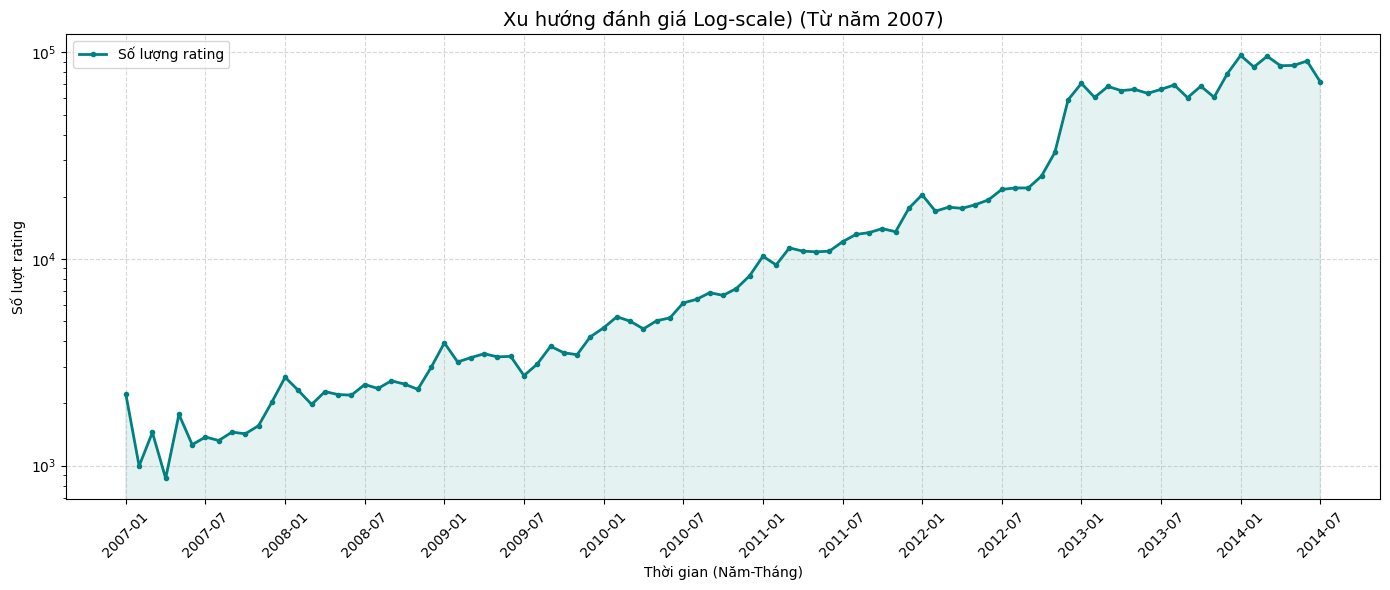

In [27]:
# Tạo điều kiện: Lấy các ngày lớn hơn hoặc bằng 01/01/2007
mask_2007 = time_col >= np.datetime64('2007-01-01')

# Áp dụng mask để tạo ra mảng dữ liệu mới đã lọc
time_filtered = time_col[mask_2007]

# Chuyển đổi về độ chính xác theo THÁNG [M]
months_only = time_filtered.astype('datetime64[M]')

# Đếm số lượng
unique_months, month_counts = np.unique(months_only, return_counts=True)

# Chuyển về string (VD: '2020-01')
month_labels = np.datetime_as_string(unique_months, unit='M')

plt.figure(figsize=(14, 6))

# Vẽ biểu đồ đường
plt.plot(month_labels, month_counts, marker='.', linestyle='-', color='teal', linewidth=2, label='Số lượng rating')
plt.fill_between(month_labels, month_counts, color='teal', alpha=0.1)

plt.yscale('log')
plt.title('Xu hướng đánh giá Log-scale) (Từ năm 2007)', fontsize=14)
plt.xlabel('Thời gian (Năm-Tháng)')
plt.ylabel('Số lượt rating')

# Tối ưu hiển thị trục X:
# Nếu dữ liệu quá dài (2007-2014 là ~84 tháng), hiển thị tất cả nhãn sẽ bị rối.
# Ta chỉ hiện nhãn của mỗi 6 tháng hoặc 12 tháng một lần cho thoáng.
total_months = len(month_labels)
if total_months > 20:
    # Lấy vị trí (index) để hiển thị nhãn: Cứ cách 6 tháng lấy 1 lần
    ticks_idx = np.arange(0, total_months, 6) 
    plt.xticks(ticks_idx, month_labels[ticks_idx], rotation=45)
else:
    plt.xticks(rotation=45)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.legend()
plt.show()

***Insight 1: Sự bùng nổ của ngành mỹ phẩm những năm 2012-2013***
- Đây là giai đoạn hoàng kim của Beauty Bloggers & YouTubers (như Michelle Phan). Xu hướng xem review trên YouTube rồi lên Amazon mua hàng trở nên phổ biến.
- Niềm tin mua hàng: Trước 2010, người ta sợ mua mỹ phẩm online (sợ hàng giả, không thử màu được). Giai đoạn 2012 đánh dấu sự chuyển dịch thói quen tiêu dùng sang mua sắm trực tuyến cho các mặt hàng chăm sóc cá nhân (Personal Care).

***Insight 2: Thói quen mua hàng của người dùng vào các dịp lễ***
- Tháng 1 (Post-Holiday Effect): Mỹ phẩm là món quà Giáng sinh/Năm mới cực phổ biến. Người dùng nhận quà tháng 12, dùng thử 2-3 tuần, và lên viết review vào tháng 1.
- Tháng 7 (Summer Season): Đây là mùa cao điểm của Kem chống nắng (Sunscreen), sản phẩm làm nâu da (Tanning) và các bộ kit du lịch. Nhu cầu mua sắm và đánh giá các mặt hàng này tăng vọt vào giữa hè.

##### **e. Phân tích kết hợp**
***<u>Câu hỏi 5</u>: Đâu là những sản phẩm hàng đầu theo Bayesian Average?***
- Lý do cho câu hỏi:
    - Điểm trung bình thông thường (Arithmetic Mean) chỉ quan tâm đến giá trị, bỏ qua số lượng.
        - Sản phẩm A: 1 đánh giá, 5 sao $\rightarrow$ Avg = 5.0 (Tuyệt đối, nhưng không tin cậy).
        - Sản phẩm B: 1,000 đánh giá, 4.8 sao $\rightarrow$ Avg = 4.8 (Thấp hơn A, nhưng cực kỳ uy tín).
    - Hậu quả: Nếu sắp xếp theo rating trung bình giảm dần, danh sách Top 100 sẽ tràn ngập các sản phẩm rác hoặc sản phẩm mới toanh chỉ có 1-2 người nhà vào khen. Các sản phẩm "bom tấn" thực sự sẽ bị chìm nghỉm.
    - Mục tiêu của chúng ta là hạ điểm của những sản phẩm ít đánh giá về mức trung bình của toàn hệ thống, và giữ nguyên điểm của những sản phẩm đã có đủ lượng đánh giá để chứng minh năng lực.
- Kết quả đạt được khi trả lời insight câu hỏi này:
    - Bảng xếp hạng công bằng (Fair Ranking): Sản phẩm đứng đầu phải thỏa mãn 2 điều kiện: Điểm cao và Nhiều người đánh giá.
    - Khử nhiễu (Noise Reduction): Loại bỏ các trường hợp "One-hit wonder" (được 5 sao do may mắn hoặc gian lận số lượng nhỏ).
    - Tăng trải nghiệm người dùng: Khi người dùng nhìn thấy Top sản phẩm, họ thấy những cái tên quen thuộc và phổ biến, tạo niềm tin vào hệ thống gợi ý.
- Để trả lời câu hỏi này, chúng ta sẽ sử dụng công thức nổi tiếng của **IMDb** (thường dùng cho Top 250 phim hay nhất) để tính điểm này.

    $$\text{Weighted Rating (WR)} = \left( \frac{v}{v+m} \cdot R \right) + \left( \frac{m}{v+m} \cdot C \right)$$

    **Trong đó:**

    * $R$ = Điểm trung bình của riêng sản phẩm đó (Product's Average Rating).
    * $v$ = Số lượng đánh giá của sản phẩm đó (Number of votes).
    * $m$ = Số lượng đánh giá tối thiểu cần có để được niêm yết (Minimum votes required). Đây là tham số làm mượt (smoothing parameter).
    * $C$ = Điểm trung bình của **toàn bộ hệ thống** (Mean vote across the whole report).

Thực hiện tính toán điểm rating trung bình cho từng sản phẩm

In [28]:
# Tính tổng rating cho mỗi sản phẩm (Sum), weights=rating_col nghĩa là thay vì đếm +1, nó cộng giá trị rating vào
rating_sums = np.bincount(prod_idx_col, weights=rating_col)

# Đếm số lượng rating cho mỗi sản phẩm (Count), weights không được cung cấp, nên mỗi lần xuất hiện sẽ được tính là +1
rating_counts = np.bincount(prod_idx_col)

# Lưu ý: Cần tránh lỗi chia cho 0 (nếu có index nào đó bị khuyết trong dãy)
# Tạo mask để chỉ tính trung bình cho những sản phẩm có rating > 0
mask = rating_counts > 0

# Khởi tạo mảng kết quả (mặc định là 0)
avg_ratings = np.zeros_like(rating_sums, dtype=float)

# Thực hiện phép chia chỉ tại những nơi có dữ liệu
avg_ratings[mask] = rating_sums[mask] / rating_counts[mask]

unique_ids = np.nonzero(mask)[0] # Lấy danh sách ID có dữ liệu
R = avg_ratings[mask]   # Lấy rating tương ứng

Thực hiện tính toán điểm Bayesian Average score cho từng sản phẩm

In [29]:
# Dùng np.mean để tính trung bình toàn cục
C = np.mean(rating_col)
print(f"Điểm trung bình của các sản phẩm trong bộ dữ liệu (C): {C:.2f}")

# Dùng np.percentile để xác định số lượng rating tối thiểu cho một sản phẩm
m = np.quantile(prod_counts, 0.9)
print(f"Ngưỡng vote tối thiểu (m): {m}")

# Tính Bayesian Rating bằng cách sử dụng broadcasting của NumPy
# Công thức: (v / (v + m) * R) + (m / (v + m) * C)
bayesian_scores = (prod_counts / (prod_counts + m) * R) + \
                  (m / (prod_counts + m) * C)

# np.argsort trả về danh sách CHỈ SỐ (index) đã được sắp xếp tăng dần
bayesian_sorted_indices = np.argsort(bayesian_scores)

# Đảo ngược lại để có thứ tự giảm dần (Descending)
bayesian_sorted_indices = bayesian_sorted_indices[::-1]

# Dùng Fancy Indexing để sắp xếp lại các mảng dữ liệu theo thứ tự điểm số
sorted_ids = prod_idx_col[bayesian_sorted_indices]
sorted_ratings = R[bayesian_sorted_indices]
sorted_votes = prod_counts[bayesian_sorted_indices]
sorted_scores = bayesian_scores[bayesian_sorted_indices]

print("\n--- Top 10 sản phẩm có Bayesian Score cao nhất ---")
print(f"{'ID':<15} {'Rating':<10} {'Votes':<10} {'Bayesian Score':<15}")
print("-" * 55)
for pid, r, v, score in zip(sorted_ids[:10], sorted_ratings[:10], sorted_votes[:10], sorted_scores[:10]):
    print(f"{prod_map[pid]:<15} {r:<10.1f} {v:<10} {score:.5f}")

Điểm trung bình của các sản phẩm trong bộ dữ liệu (C): 4.15
Ngưỡng vote tối thiểu (m): 15.0

--- Top 10 sản phẩm có Bayesian Score cao nhất ---
ID              Rating     Votes      Bayesian Score 
-------------------------------------------------------
B000F37UNM      4.9        398        4.86256
B000FLJQTA      5.0        85         4.85236
B000FCY95A      4.9        172        4.85153
B000EODWZW      4.9        426        4.84407
B00028NL5Q      4.9        98         4.84279
B000EVGQ0S      5.0        79         4.83229
B000FFI228      4.9        239        4.83164
B000C1UEAI      4.9        88         4.82753
B0006NY35E      5.0        58         4.82514
B000B8FW0Y      4.9        123        4.81330



***Insight 1: Cho mục đích "Bảng Xếp Hạng Uy Tín" (Top Charts/Best Sellers):***
- Mức 0.9 đảm bảo Top 10 là những sản phẩm có chất lượng thực sự. 
- Khách hàng nhìn vào thấy số lượng vote hàng trăm, họ sẽ rất tin tưởng. 

$\Rightarrow$ Danh sách này an toàn để hiển thị trên trang chủ.

***Insight 2: Cho mục đích "Gợi ý Cá nhân hóa" (Personalized Recs):***
- Tuy nhiên, danh sách này sẽ hơi quá khắt khe, nếu dùng mức này để lọc sản phẩm gợi ý cho từng cá nhân, rất nhiều các sản phẩm tiềm năng sẽ bị bỏ lỡ(những món mới ra mắt, có 5-10 vote rất tốt nhưng chưa đủ 15).
- Với gợi ý cá nhân, nên hạ $m$ xuống mức quantile 0.5 hoặc 0.75 để tăng độ đa dạng (Diversity).


### **V. Xuất các cột dữ liệu đã được xử lý**

In [30]:
np.savez('../data/processed/dataset.npz', 
         user_idx=user_idx_col,
         user_map=user_map,
         prod_idx=prod_idx_col, 
         prod_map=prod_map,
         rating_col=rating_col,
         time_col=time_col
         )

print("Đã lưu xong!")

Đã lưu xong!
